## Step 1. Load the data

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyfixest as pf
from pathlib import Path
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
FIG_DIR = Path("..") / "Figures"      
FIG_DIR.mkdir(exist_ok=True)

REF_YEAR = 2016
TREATS = ["did_2017", "did_2018"]
CLUSTER = {"CRV1": "unitid"}

RACES = {
    "American Indian or Alaska Native": "AIAN",
    "Asian": "Asian",
    "Black or African American": "Black",
    "Hispanic": "Hispanic",
    "Native Hawaiian or Other Pacific Islander": "NHPI",
    "White": "White",
    "Two or more races": "Multi",
}

panel = pd.read_csv(Path("..") / "Data Cleaning" / "panel_clean.csv")
cols = [f"{race} {sex}" for race in RACES for sex in ["total", "men", "women"]]
df = panel[["unitid", "fall_year", "state"] + cols].copy()

df["treated"] = (df["state"] == "NY").astype(int)
df["did_2017"] = df["treated"] * (df["fall_year"] >= 2017)
df["did_2018"] = df["treated"] * (df["fall_year"] >= 2018)

YEARS = sorted(df["fall_year"].unique())
EV_YEARS = [y for y in YEARS if y != REF_YEAR]
PRE_YEARS = [y for y in EV_YEARS if y < REF_YEAR]

## Step 2. Reshape and set up the tools

One row per institution × year × group. Outcome: $y = \ln(1 + \text{enrollment})$.

**Effect coding:** each group gets a column that is +1 for that group, −1 for one group set aside for coding, and 0 otherwise. Each coefficient is then that group's distance from the average of all groups.

In [2]:
long = df.melt(id_vars=["unitid", "fall_year", "treated"] + TREATS,
               value_vars=cols, var_name="col", value_name="count")
long["race"] = long["col"].map(lambda c: RACES[c.rsplit(" ", 1)[0]])
long["sex"] = long["col"].str.rsplit(" ", n=1).str[1]
long["cell"] = long["race"] + "_" + long["sex"]
long["y"] = np.log1p(long["count"])

race_long = long[long["sex"] == "total"].copy()    # 7 racial groups
cell_long = long[long["sex"] != "total"].copy()    # 14 race x gender groups

In [4]:
def wald(fit, terms):
    names = list(fit.coef().index)
    R = np.zeros((len(terms), len(names)))
    for i, t in enumerate(terms):
        R[i, names.index(t)] = 1
    w = fit.wald_test(R=R)
    return float(np.ravel(w["statistic"])[0]), float(np.ravel(w["pvalue"])[0])


def holm(p):
    return multipletests(p, method="holm")[1]


def add_effect_codes(data, group_col, omit):
    d = data.copy()
    codes = []
    for g in sorted(d[group_col].unique()):
        if g != omit:
            d[f"e_{g}"] = np.where(d[group_col] == g, 1, np.where(d[group_col] == omit, -1, 0))
            codes.append(f"e_{g}")
    return d, codes


def deviations(data, group_col, treat, fe_col=None):
    # DiD: each group's effect minus the average effect (fit twice so every group gets an estimate)
    fe_col = fe_col or group_col
    groups = sorted(data[group_col].unique())
    rows = []
    for omit in [groups[-1], groups[0]]:
        d, codes = add_effect_codes(data, group_col, omit)
        terms = []
        for c in codes:
            d[f"D_{c}"] = d[treat] * d[c]
            terms.append(f"D_{c}")
        fit = pf.feols(f"y ~ {treat} + {' + '.join(terms)} | unitid^{fe_col} + fall_year^{fe_col}",
                       data=d, vcov=CLUSTER)
        for g in groups:
            n = f"D_e_{g}"
            if n in fit.coef().index and g not in [r["Group"] for r in rows]:
                rows.append({"Group": g, "Treatment": treat, "Gap": fit.coef()[n],
                             "SE": fit.se()[n], "p": fit.pvalue()[n]})
    out = pd.DataFrame(rows)
    out["p (Holm)"] = holm(out["p"])
    return out


def deviation_event_study(data, group_col, fe_col=None):
    fe_col = fe_col or group_col
    groups = sorted(data[group_col].unique())
    paths, tests, done = [], [], set()
    for omit in [groups[-1], groups[0]]:
        d, codes = add_effect_codes(data, group_col, omit)
        terms = []
        for k in EV_YEARS:
            d[f"ev{k}"] = d["treated"] * (d["fall_year"] == k)
            terms.append(f"ev{k}")
            for c in codes:
                d[f"ev{k}_{c}"] = d[f"ev{k}"] * d[c]
                terms.append(f"ev{k}_{c}")
        fit = pf.feols(f"y ~ {' + '.join(terms)} | unitid^{fe_col} + fall_year^{fe_col}",
                       data=d, vcov=CLUSTER)
        for g in groups:
            if g in done or f"ev{EV_YEARS[0]}_e_{g}" not in fit.coef().index:
                continue
            done.add(g)
            for k in EV_YEARS:
                n = f"ev{k}_e_{g}"
                paths.append({"Group": g, "Year": k, "Gap": fit.coef()[n], "SE": fit.se()[n]})
            chi2, p = wald(fit, [f"ev{k}_e_{g}" for k in PRE_YEARS])
            tests.append({"Group": g, "Pre-trend chi2(4)": chi2, "p": p})
    tests = pd.DataFrame(tests)
    tests["p (Holm)"] = holm(tests["p"])
    return pd.DataFrame(paths), tests


def plot_paths(paths, fname, ylabel):
    groups = list(dict.fromkeys(paths["Group"]))
    ncols = min(4, len(groups))
    nrows = int(np.ceil(len(groups) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), sharex=True, squeeze=False)
    for ax, g in zip(axes.flat, groups):
        s = pd.concat([paths[paths["Group"] == g],
                       pd.DataFrame([{"Group": g, "Year": REF_YEAR, "Gap": 0, "SE": 0}])]).sort_values("Year")
        ax.errorbar(s["Year"], s["Gap"], yerr=1.96 * s["SE"], fmt="o-", capsize=3)
        ax.axhline(0, color="grey", linewidth=0.8)
        ax.axvline(REF_YEAR + 0.5, color="red", linestyle="--")
        ax.set_title(g)
    for ax in axes.flat[len(groups):]:
        ax.set_visible(False)
    fig.supylabel(ylabel)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=300)
    plt.show()

## Step 3. Parallel trends by racial group

For each group: were its 2012–2015 gaps from the average jointly zero? (Holm-corrected across the 7 groups.)

,Group,Pre-trend chi2(4),p,p (Holm)
0,AIAN,9.941,0.041,0.290
1,Asian,3.801,0.434,1.000
2,Black,6.567,0.161,0.642
3,Hispanic,3.112,0.539,1.000
4,Multi,8.243,0.083,0.493
5,NHPI,2.249,0.690,1.000
6,White,8.271,0.082,0.493


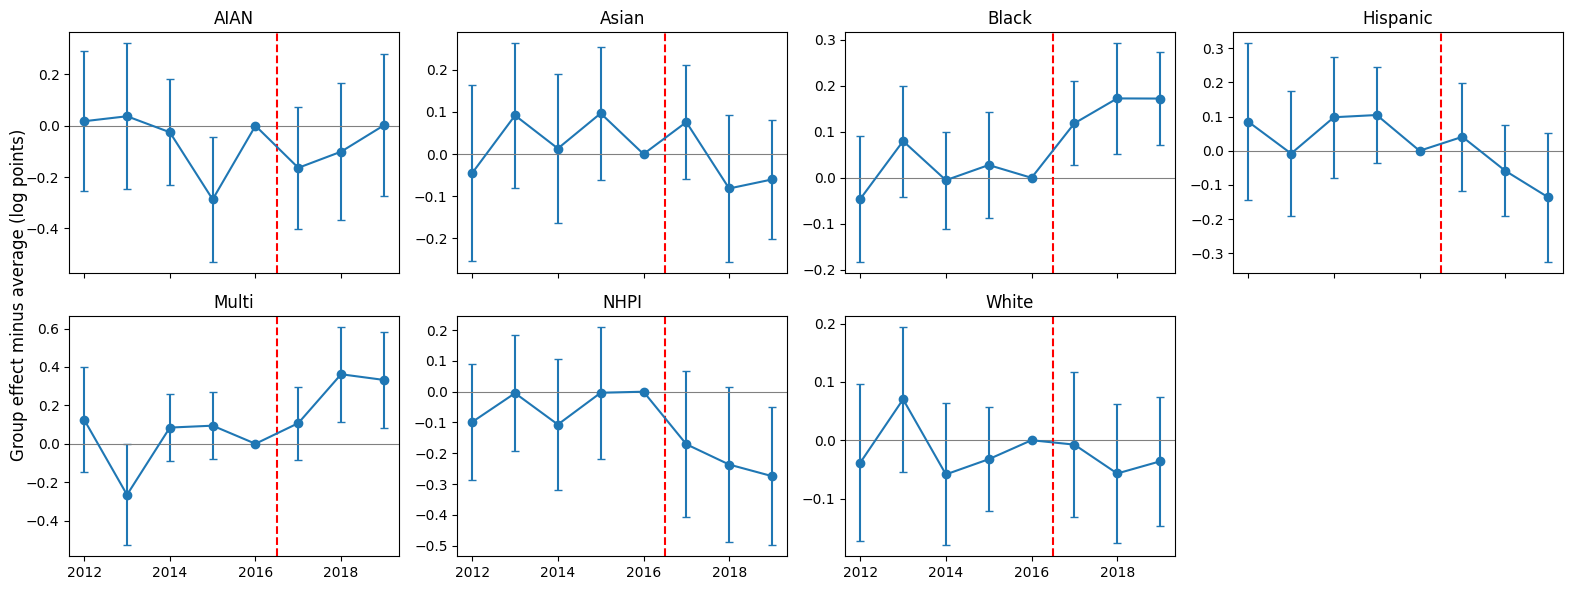

In [5]:
race_paths, race_pretests = deviation_event_study(race_long, "race")
display(race_pretests.round(3))
plot_paths(race_paths, "race_pretrends_event_study.png", "Group effect minus average (log points)")

## Step 4. Parallel trends for the gender gap

,Group,Pre-trend chi2(4),p,p (Holm)
0,men,6.002,0.199,0.398


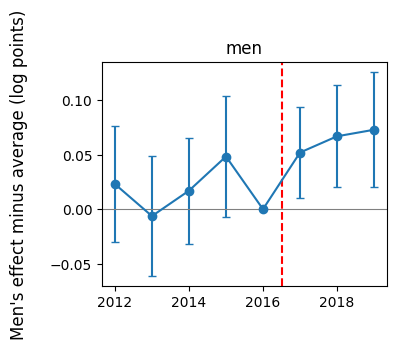

In [6]:
sex_paths, sex_pretests = deviation_event_study(cell_long, "sex", fe_col="cell")
display(sex_pretests[sex_pretests["Group"] == "men"].round(3))
plot_paths(sex_paths[sex_paths["Group"] == "men"], "gender_pretrends_event_study.png",
           "Men's effect minus average (log points)")

## Step 5. Race × gender effects

Each of the 14 groups' Excelsior effect minus the average of all 14 groups. \* = Holm-adjusted p < 0.05.

In [7]:
cells = pd.concat([deviations(cell_long, "cell", t) for t in TREATS], ignore_index=True)
cells[["Race", "Gender"]] = cells["Group"].str.split("_", expand=True)

cells["value"] = cells.apply(lambda r: f"{r['Gap']:.3f}" + ("*" if r["p (Holm)"] < 0.05 else ""), axis=1)
cells["column"] = cells["Gender"].str.capitalize() + ", " + cells["Treatment"].str[-4:]
table = (cells.pivot(index="Race", columns="column", values="value")
              .loc[["Black", "Multi", "White", "Asian", "Hispanic", "AIAN", "NHPI"],
                   ["Men, 2017", "Women, 2017", "Men, 2018", "Women, 2018"]])
display(table)

column,"Men, 2017","Women, 2017","Men, 2018","Women, 2018"
Race,,,,
Black,0.173*,0.120,0.183*,0.123
Multi,0.275,0.206,0.331*,0.267
White,0.015,-0.062,0.010,-0.072
Asian,0.041,-0.132,-0.022,-0.183
Hispanic,-0.074,-0.130,-0.104,-0.173
AIAN,0.082,-0.151,0.106,-0.106
NHPI,-0.179,-0.184,-0.171,-0.189


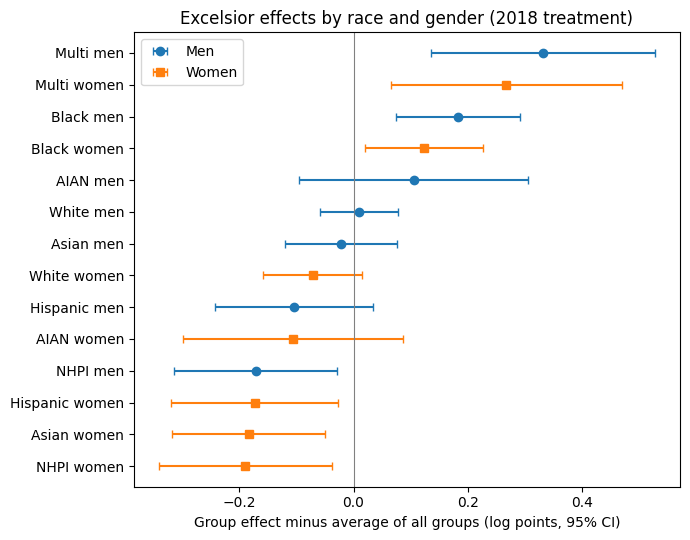

In [8]:
s = cells[cells["Treatment"] == "did_2018"].sort_values("Gap").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 5.5))
for g, marker in [("men", "o"), ("women", "s")]:
    q = s[s["Gender"] == g]
    ax.errorbar(q["Gap"], q.index, xerr=1.96 * q["SE"], fmt=marker, capsize=3, label=g.capitalize())
ax.set_yticks(s.index)
ax.set_yticklabels(s["Race"] + " " + s["Gender"])
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Group effect minus average of all groups (log points, 95% CI)")
ax.set_title("Excelsior effects by race and gender (2018 treatment)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "race_gender_effects.png", dpi=300)
plt.show()

## Step 6. Interaction effects

- **Men − women gap:** men are coded +1 and women −1, so the gap is 2 × men's distance from the average.
- **Does the gender gap differ by race?** Joint Wald test that all race × gender interaction terms are zero, χ²(6).

In [9]:
rows = []
for t in TREATS:
    # Men - women gap
    men = deviations(cell_long, "sex", t, fe_col="cell").query("Group == 'men'").iloc[0]
    gap, se = 2 * men["Gap"], 2 * men["SE"]

    # Race x gender interaction test
    d, race_codes = add_effect_codes(cell_long, "race", omit="White")   # left-out group doesn't matter
    d["e_men"] = np.where(d["sex"] == "men", 1, -1)
    d["D_men"] = d[t] * d["e_men"]
    main, inter = [t, "D_men"], []
    for c in race_codes:
        d[f"D_{c}"] = d[t] * d[c]
        d[f"D_{c}_men"] = d[t] * d[c] * d["e_men"]
        main.append(f"D_{c}")
        inter.append(f"D_{c}_men")
    fit = pf.feols(f"y ~ {' + '.join(main + inter)} | unitid^cell + fall_year^cell", data=d, vcov=CLUSTER)
    chi2, p_int = wald(fit, inter)

    rows.append({"Treatment": t[-4:],
                 "Men - women gap": round(gap, 3),
                 "95% CI": f"{gap - 1.96 * se:.3f} to {gap + 1.96 * se:.3f}",
                 "Gap p": round(men["p"], 3),
                 "Interaction chi2(6)": round(chi2, 2),
                 "Interaction p": round(p_int, 3)})

interaction = pd.DataFrame(rows)
display(interaction)

,Treatment,Men - women gap,95% CI,Gap p,Interaction chi2(6),Interaction p
0,2017,0.095,0.044 to 0.146,0.000,6.16,0.406
1,2018,0.095,0.038 to 0.152,0.001,3.22,0.781
